# 03 — Tuning gain and pulse width

Companion notebook to *Turning the knobs* (`docs/substack/03-turning-the-knobs.md`).
pic0rick python library **v0.1.8**. Offline by default (recorded sweeps on the 10 mm step).

In [1]:
# --- common setup: find the repo, import the pic0rick library, pin the version
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

REPO = next(p for p in pathlib.Path.cwd().resolve().parents if (p / "python" / "pic0rick").is_dir())
sys.path.insert(0, str(REPO / "python"))
import pic0rick

WRITTEN_FOR = "0.1.8"   # pic0rick python library version this notebook was written against
print("pic0rick python library:", pic0rick.__version__, "(notebook written for", WRITTEN_FOR + ")")
if pic0rick.__version__ != WRITTEN_FOR:
    print("WARNING: library version differs -- the API may have moved, check python/Readme.md")

FIG = pathlib.Path("../images"); FIG.mkdir(exist_ok=True)
DATA = REPO / "docs" / "data"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.grid": True, "grid.alpha": 0.3})

LIVE = False   # set True with a pic0rick (firmware -DDSP build, v0.1.11+) plugged in

pic0rick python library: 0.1.8 (notebook written for 0.1.8)


In [2]:
from pic0rick.ndt_acquisition import UltrasonicAcquisition, load_h5
H5 = DATA / "calibration_block_5steps_1018steel.h5"
acqs = load_h5(str(H5))
for x in acqs:
    x.piezo_central_freq, x.piezo_bandwidth = 5e6, 4e6

## 1. Gain sweep (the AD8331 TGC)

The DAC value (0–1023) sets the AD8331 gain (≈7.5 → 55.5 dB across its range).
Live, the sweep is just a loop over `from_probe(gain=…)`.

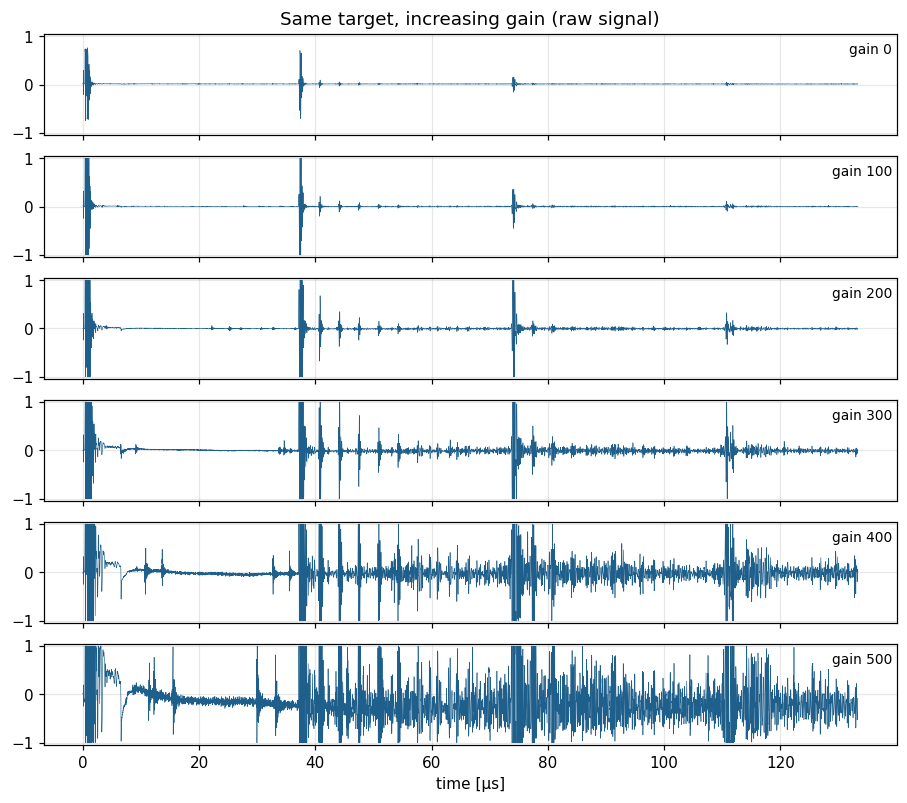

In [3]:
if LIVE:
    sweep = [UltrasonicAcquisition.from_probe(Fech=60e6, gain=g, pon=70, poff=70, damp=6000,
                                              target="steel ~10mm", h5_path="gain_sweep.h5")
             for g in (0, 100, 200, 300, 400, 500)]
    for x in sweep: x.piezo_central_freq, x.piezo_bandwidth = 5e6, 4e6
else:
    sweep = sorted([x for x in acqs if x.pon == 70 and "10.0mm" in x.target], key=lambda x: x.gain)

fig, axes = plt.subplots(len(sweep), 1, figsize=(10, 1.4 * len(sweep)), sharex=True, sharey=True)
for ax, x in zip(axes, sweep):
    ax.plot(x.t * 1e6, x.signal, lw=0.4, color="#1f5f8b")
    ax.text(0.995, 0.8, f"gain {int(x.gain)}", transform=ax.transAxes, ha="right", fontsize=9)
    ax.set_ylim(-1.05, 1.05)
axes[0].set_title("Same target, increasing gain (raw signal)")
axes[-1].set_xlabel("time [µs]")
fig.savefig(FIG / "03-gain-sweep.png")

Quantify it: peak amplitude of the first echo, the amount of the record that is clipped, and
the noise floor in the quiet gap before the echoes (20–28 µs).

gain    0  first echo  0.71  clipped  0.00%  noise 0.0015
gain  100  first echo  1.00  clipped  0.60%  noise 0.0021
gain  200  first echo  1.00  clipped  1.00%  noise 0.0079
gain  300  first echo  1.00  clipped  1.74%  noise 0.0059
gain  400  first echo  1.00  clipped  3.38%  noise 0.0178
gain  500  first echo  1.00  clipped  5.71%  noise 0.0436


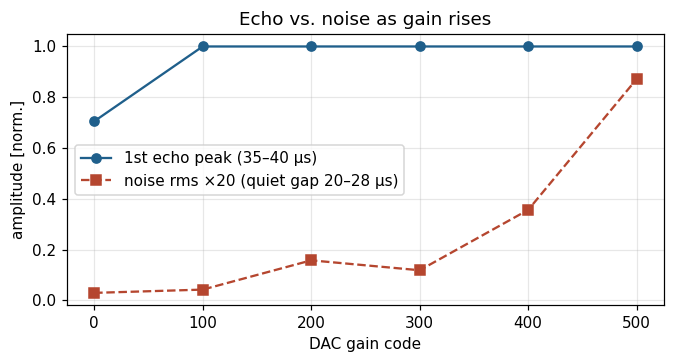

In [4]:
rows = []
for x in sweep:
    t = x.t * 1e6
    first = x.amplitude(35, 40, filtered=False)
    clip = np.mean(np.abs(x.signal) > 0.98) * 100
    noise = x.signal[(t > 20) & (t < 28)].std()
    rows.append((int(x.gain), first, clip, noise))
    print(f"gain {int(x.gain):4d}  first echo {first:5.2f}  clipped {clip:5.2f}%  noise {noise:.4f}")
g, first, clip, noise = map(np.array, zip(*rows))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(g, first, "o-", label="1st echo peak (35–40 µs)", color="#1f5f8b")
ax.plot(g, noise * 20, "s--", label="noise rms ×20 (quiet gap 20–28 µs)", color="#b5462f")
ax.set(xlabel="DAC gain code", ylabel="amplitude [norm.]", title="Echo vs. noise as gain rises")
ax.legend()
fig.savefig(FIG / "03-gain-metrics.png")

## 2. Pulse-width sweep

The pulser drives a three-level pulse; `pon`/`poff` are the half-widths in ns. A transducer
rings best when the half-period matches it: for 5 MHz, half a period is **100 ns**.
`UltrasonicAcquisition.calibrate()` automates the sweep live; here we reuse its recorded output.

pulse widths [ns]: [ 25  35  45  55  65  75  85  95 105 115 125 135 145 155]
best pon = poff  : 95 ns  -> equivalent centre frequency 5.26 MHz


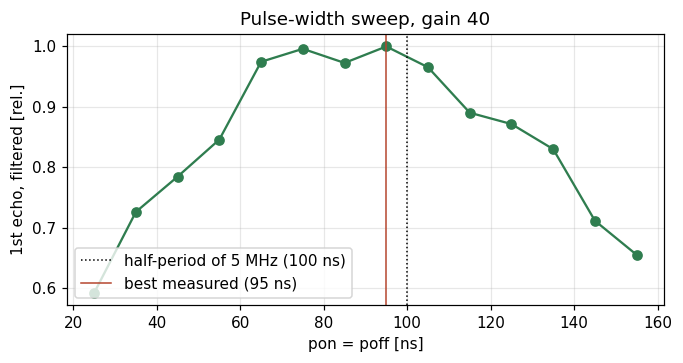

In [5]:
if LIVE:
    calib = UltrasonicAcquisition.calibrate("pulse_sweep.h5", Fech=60e6, start_us=35, end_us=40, gain=40,
                                            piezo_central_freq=5e6, piezo_bandwidth=4e6,
                                            target="steel ~10mm - calibration")
    print("best pon=poff:", calib["best_pon_poff"])
pulse = sorted([x for x in acqs if "calibration" in x.target], key=lambda x: x.pon)
pw = np.array([x.pon for x in pulse])
amp = np.array([x.amplitude(35, 40) for x in pulse])
best = pw[np.argmax(amp)]
print("pulse widths [ns]:", pw)
print("best pon = poff  :", best, "ns  -> equivalent centre frequency %.2f MHz" % (1e3 / (2 * best)))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(pw, amp / amp.max(), "o-", color="#2f7d4f")
ax.axvline(100, color="k", ls=":", lw=1, label="half-period of 5 MHz (100 ns)")
ax.axvline(best, color="#b5462f", lw=1, label=f"best measured ({best} ns)")
ax.set(xlabel="pon = poff [ns]", ylabel="1st echo, filtered [rel.]", title="Pulse-width sweep, gain 40")
ax.legend()
fig.savefig(FIG / "03-pulse-sweep.png")

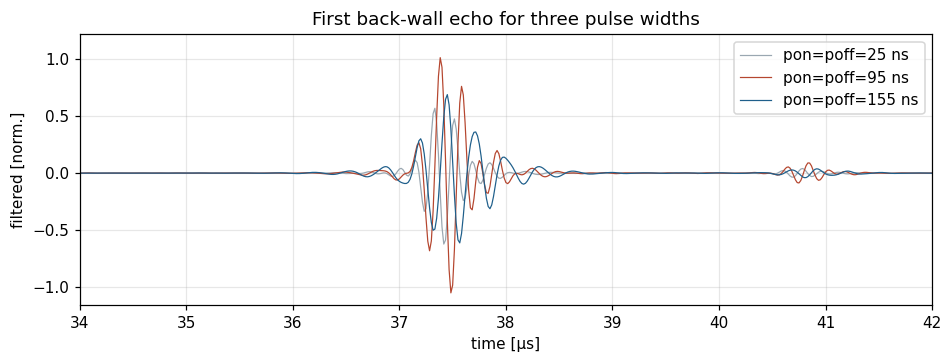

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for x, c in zip([pulse[0], next(p for p in pulse if p.pon == best), pulse[-1]], ["#9aa7b1", "#b5462f", "#1f5f8b"]):
    ax.plot(x.t * 1e6, x.signal_filtered, lw=0.8, color=c, label=f"pon=poff={x.pon} ns")
ax.set(xlim=(34, 42), xlabel="time [µs]", ylabel="filtered [norm.]", title="First back-wall echo for three pulse widths")
ax.legend()
fig.savefig(FIG / "03-pulse-echoes.png")